# EDA v2 — Toutes nos variables réunies, et ce qu'elles nous apprennent

**Groupe :** Maxime, Loan, Moussa, Mouhamedou et Ousmane — assemblage réalisé par Loan

## Rappel : c'est quoi l'Elo, et pourquoi plusieurs Elo ?

**L'Elo est une note de niveau** (la méthode standard des échecs, du classement FIFA ou des jeux vidéo). Après chaque match, le club gagne des points s'il gagne et en perd s'il perd, **d'autant plus que le résultat est une surprise** : battre un club plus fort rapporte beaucoup, battre un club plus faible rapporte peu. Et un **nul** fait perdre des points au favori et en fait gagner à l'outsider.

**Ce qu'on a fait (`v2_elo.ipynb`) :** l'Elo officiel (`EloRatings.csv`) ne couvrait que 80 % des matchs et mélangeait championnat et C1. On a donc calculé nos propres Elo, puis construit un **Elo complet**, comme le prof l'a demandé :

| Elo | Comment il est obtenu | Matchs de C1 bien prédits par « le meilleur Elo gagne » |
|---|---|---|
| **Complet** (le nôtre, final) | Elo officiel quand il existe ; sinon estimé d'après les résultats du club contre des clubs à Elo connu | **57,8 %**, sur **100 %** des matchs |
| Global (maison) | Calculé sur tous les matchs de clubs, départ à 1 500 | 56,0 % |
| C1 (maison) | Seulement les matchs de C1 | 55,8 % |
| Championnat (maison) | Seulement les matchs de championnat | 48,2 %, pas mieux que « le domicile gagne » |

**Ce qu'il faut retenir :**
- l'Elo est toujours pris **avant** le match, pour ne pas utiliser le résultat qu'on cherche à prédire ;
- l'**Elo complet** ne laisse **aucun club de côté** et remet chacun **à sa place** : notre Elo maison surestimait les petits clubs (+67 points) et sous-estimait les grands (−119) ;
- l'Elo **championnat** ne marche pas pour la C1 : il compare chaque club à son propre pays (1 800 points en Norvège ≠ 1 800 en Allemagne).

## La question
Dans l'EDA v1, on a vu que l'**Elo** est la variable la plus utile pour prédire un match de C1. Le prof nous a demandé d'aller plus loin : séparer l'Elo C1 et l'Elo championnat, ne laisser aucun club sans Elo, regarder les **joueurs**, la **fatigue**, faire un `describe()` et une **matrice de corrélation**, et ne pas traiter un **nul** comme une simple « demi-victoire ».

Chaque membre a préparé une partie dans son propre notebook. Ce notebook les **réunit** et répond à une question : **quelles variables sont vraiment liées au résultat d'un match, et lesquelles disent la même chose ?**

## Les données utilisées
| Fichier | Préparé par | Une ligne = | Ce qu'il apporte |
|---|---|---|---|
| `output/elo_par_match.csv` | Moussa (`v2_elo.ipynb`) | un match | Elo complet, global, C1 et championnat des deux clubs, **avant** le match, et terrain neutre ou non |
| `output/joueurs_par_match.csv` | Mouhamedou (`v2_joueurs.ipynb`) | une équipe dans un match | valeur de l'effectif avant le match, âge, rotation et meilleur buteur de la saison précédente |
| `output/fatigue_par_match.csv` | Ousmane (`v2_fatigue.ipynb`) | une équipe dans un match | jours de repos et matchs joués dans les 30 jours avant |

Ces fichiers ne sont pas dans Git : il faut d'abord exécuter les 3 notebooks ci-dessus pour les créer. Les fichiers de Maxime (participants et calendrier 2026-2027) ne servent pas ici : ils concernent des matchs futurs, sans résultat.

**Résultat de ce notebook :** une grande table, `output/eda_matchs_c1.csv`, avec **une ligne par match** et toutes les variables. C'est la table que le modèle utilisera.

## Plan
1. Vérifier les fichiers avant de les réunir
2. Passer d'une ligne par équipe à une ligne par match
3. Construire les écarts, le résultat attendu et la surprise
4. `describe()` : ordres de grandeur et valeurs bizarres
5. Matrice de corrélation
6. Quelles variables sont liées au résultat ?
7. Quelles variables se répètent ?
8. Interprétation
9. Limite : la météo
10. Corrélation ≠ causalité
11. Conclusion

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DOSSIER_PROJET = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "output").is_dir()), None)
if DOSSIER_PROJET is None:
    raise FileNotFoundError("Dossier output/ introuvable. Exécute d'abord les notebooks Elo, joueurs et fatigue en local.")
OUT = DOSSIER_PROJET / "output"

FICHIERS = ["elo_par_match.csv", "joueurs_par_match.csv", "fatigue_par_match.csv"]
manquants = [f for f in FICHIERS if not (OUT / f).is_file()]
if manquants:
    raise FileNotFoundError("Fichier(s) absent(s) de output/ : " + ", ".join(manquants)
                            + ". Exécute le notebook correspondant en local.")

elo = pd.read_csv(OUT / "elo_par_match.csv", parse_dates=["date"], encoding="utf-8-sig")
joueurs = pd.read_csv(OUT / "joueurs_par_match.csv", parse_dates=["date"], encoding="utf-8-sig")
fatigue = pd.read_csv(OUT / "fatigue_par_match.csv", parse_dates=["date"], encoding="utf-8-sig")
print(f"elo : {len(elo):,} lignes | joueurs : {len(joueurs):,} | fatigue : {len(fatigue):,}")

elo : 1,871 lignes | joueurs : 3,742 | fatigue : 3,742


## 1. Vérifier les fichiers avant de les réunir

**Question :** les trois fichiers ont-ils la forme attendue ? Si un match était présent deux fois, la fusion créerait des doublons sans prévenir.

**Ce qu'on attend :** un match apparaît **une fois** dans le fichier Elo (une ligne = un match), et **deux fois** dans les fichiers joueurs et fatigue (une ligne par équipe).

**Résultat :** les trois fichiers sont conformes. On a bien **1 871 matchs**, sur les 14 saisons de 2012-2013 à 2025-2026, comme dans l'EDA v1.

Les `assert` du code arrêtent le notebook avec un message clair si un fichier n'a pas la bonne forme : on ne peut pas continuer avec des données fausses sans s'en rendre compte.

In [2]:
assert elo["game_id"].is_unique, "Un match est présent plusieurs fois dans elo_par_match.csv"
assert joueurs.groupby("game_id").size().eq(2).all(), "joueurs_par_match.csv : pas exactement 2 lignes par match"
assert fatigue.groupby("game_id").size().eq(2).all(), "fatigue_par_match.csv : pas exactement 2 lignes par match"
print("Structure conforme.")
print(f"Matchs de C1 dans elo : {elo['game_id'].nunique():,}")
print(f"Saisons : {sorted(elo['season'].unique())}")

Structure conforme.
Matchs de C1 dans elo : 1,871
Saisons : [np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


## 2. Passer d'une ligne par équipe à une ligne par match

**Problème :** les fichiers joueurs et fatigue ont **deux lignes par match** (une par équipe), alors que le fichier Elo n'en a qu'**une**. Pour les réunir, il faut la même forme partout.

**Solution :** la fonction `par_cote` met la ligne de l'équipe à domicile et celle de l'équipe à l'extérieur **côte à côte**, dans des colonnes `dom_…` et `ext_…`. On fusionne ensuite les trois tableaux sur `game_id`, l'identifiant du match.

**Vérification :** on contrôle que le club à domicile est bien **le même** dans les trois fichiers. Si un fichier avait inversé domicile et extérieur, toutes nos comparaisons seraient fausses.

**Résultat :** le club à domicile est identique dans **100 %** des matchs. La grande table fait **1 871 matchs × 41 colonnes**.

In [3]:
def par_cote(df, colonne_cote, valeur_dom, valeur_ext, colonnes, prefixe):
    # Une ligne par équipe -> une ligne par match, avec colonnes dom_<prefixe>… et ext_<prefixe>…
    morceaux = []
    for valeur, nom in [(valeur_dom, "dom"), (valeur_ext, "ext")]:
        t = df.loc[df[colonne_cote].eq(valeur), ["game_id"] + colonnes]
        morceaux.append(t.rename(columns={c: f"{nom}_{prefixe}{c}" for c in colonnes}))
    return morceaux[0].merge(morceaux[1], on="game_id", how="outer", validate="one_to_one")

cols_joueurs = [
    "club_id", "valeur_effectif_eur_avant_match", "age_moyen_joueurs_alignes",
    "nb_joueurs_utilises_championnat_precedent", "nb_joueurs_utilises_c1_precedent",
    "part_buts_meilleur_buteur_championnat_precedente", "part_buts_meilleur_buteur_c1_precedente",
    "buts_pour", "buts_contre", "resultat",
]
cols_fatigue = ["club_id", "jours_repos", "matchs_30j_avant", "couverture_championnat_detectee"]

g = elo.merge(par_cote(joueurs, "lieu", "Domicile", "Extérieur", cols_joueurs, "j_"),
              on="game_id", how="left", validate="one_to_one")
g = g.merge(par_cote(fatigue, "cote", "Domicile", "Extérieur", cols_fatigue, "f_"),
            on="game_id", how="left", validate="one_to_one")

# Contrôle : le club de domicile est bien le même dans les trois fichiers
print(f"Club domicile identique (elo / joueurs) : {(g['dom_j_club_id'] == g['home_club_id']).mean():.1%}")
print(f"Club domicile identique (elo / fatigue) : {(g['dom_f_club_id'] == g['home_club_id']).mean():.1%}")
print(f"Grande table : {g.shape[0]:,} matchs × {g.shape[1]} colonnes")

Club domicile identique (elo / joueurs) : 100.0%
Club domicile identique (elo / fatigue) : 100.0%
Grande table : 1,871 matchs × 46 colonnes


## 3. Construire les écarts, le résultat attendu et la surprise

**Idée :** ce qui compte pour prédire un match, ce n'est pas le niveau d'une équipe toute seule, mais **la différence avec son adversaire**. On calcule donc des **écarts**, toujours **domicile moins extérieur** : un écart positif veut dire que l'équipe à domicile est « au-dessus ».

**Comment on mesure le résultat (remarque du prof sur le nul) :** un nul n'a pas la même valeur pour tout le monde. Un nul de Sabah contre le Bayern est presque une victoire ; un nul du Bayern contre Sabah est presque une défaite. On utilise donc **trois façons** de décrire le résultat :
- **`resultat`**, en **3 catégories** (victoire domicile, nul, victoire extérieur) : le nul est une **issue à part**, pas une demi-victoire. C'est la cible du futur modèle ;
- **`score_domicile`** (1 / 0,5 / 0), gardé seulement pour classer les résultats dans l'ordre : défaite < nul < victoire ;
- **`surprise_domicile`** = résultat réel − résultat **attendu** d'après l'Elo complet (avec 60 points de bonus à domicile, sauf sur terrain neutre). Un nul vaut alors **environ −0,35 pour un grand favori** et **+0,28 pour un grand outsider** dans nos données : exactement ce que demande le prof.

**Trois autres choix importants :**
- **la valeur de l'effectif** varie énormément (de quelques millions à plus de 600 millions d'euros). On utilise son **logarithme** : un écart de 1 veut dire qu'un effectif vaut **10 fois** plus que l'autre ;
- **le repos et les matchs sur 30 jours** ne sont calculés que si le championnat **des deux clubs** est dans nos données. Sinon, leurs matchs de championnat sont invisibles et ils paraissent reposés à tort (le biais trouvé par Ousmane). On garde ainsi **1 566 matchs sur 1 871** pour ces deux variables ;
- **le nombre de compétitions de la saison n'est pas utilisé** : il compte des matchs qui n'ont pas encore eu lieu. C'est une **fuite d'information**, interdite pour le modèle.

**Résultat :** **12 variables explicatives**, plus le score et la surprise.

In [4]:
# Cohérence : une victoire de l'un est une défaite de l'autre
verif = g["dom_j_resultat"].map({"Victoire": 1.0, "Nul": 0.5, "Défaite": 0.0}) \
      + g["ext_j_resultat"].map({"Victoire": 1.0, "Nul": 0.5, "Défaite": 0.0})
assert verif.dropna().eq(1).all(), "Résultats incohérents entre les deux équipes"

g["score_domicile"] = g["dom_j_resultat"].map({"Victoire": 1.0, "Nul": 0.5, "Défaite": 0.0})

g["ecart_elo_global"] = g["home_elo_global"] - g["away_elo_global"]
g["ecart_elo_c1"] = g["home_elo_c1"] - g["away_elo_c1"]
g["ecart_elo_championnat"] = g["home_elo_champ"] - g["away_elo_champ"]
g["ecart_elo_complet"] = g["home_elo_complet"] - g["away_elo_complet"]

# Résultat attendu selon l'Elo complet (bonus de 60 points à domicile, sauf sur terrain neutre)
bonus_domicile = np.where(g["neutre"], 0, 60)
g["attendu_domicile"] = 1 / (1 + 10 ** (-(g["ecart_elo_complet"] + bonus_domicile) / 400))
# La surprise = réel − attendu : un nul vaut environ +0,4 pour un gros outsider et −0,4 pour un gros favori
g["surprise_domicile"] = g["score_domicile"] - g["attendu_domicile"]
# Le résultat en 3 catégories : le nul est une issue à part, pas une demi-victoire
g["resultat"] = g["dom_j_resultat"].map({"Victoire": "Victoire domicile", "Nul": "Nul", "Défaite": "Victoire extérieur"})

val_dom = g["dom_j_valeur_effectif_eur_avant_match"].where(lambda x: x > 0)
val_ext = g["ext_j_valeur_effectif_eur_avant_match"].where(lambda x: x > 0)
g["ecart_log_valeur_effectif"] = np.log10(val_dom) - np.log10(val_ext)

g["ecart_age_moyen"] = g["dom_j_age_moyen_joueurs_alignes"] - g["ext_j_age_moyen_joueurs_alignes"]
g["ecart_rotation_championnat"] = (g["dom_j_nb_joueurs_utilises_championnat_precedent"]
                                   - g["ext_j_nb_joueurs_utilises_championnat_precedent"])
g["ecart_rotation_c1"] = g["dom_j_nb_joueurs_utilises_c1_precedent"] - g["ext_j_nb_joueurs_utilises_c1_precedent"]
g["ecart_meilleur_buteur_championnat"] = (g["dom_j_part_buts_meilleur_buteur_championnat_precedente"]
                                          - g["ext_j_part_buts_meilleur_buteur_championnat_precedente"])
g["ecart_meilleur_buteur_c1"] = (g["dom_j_part_buts_meilleur_buteur_c1_precedente"]
                                 - g["ext_j_part_buts_meilleur_buteur_c1_precedente"])

# Repos : seulement si le championnat des DEUX clubs est dans games.csv (sinon « faux repos », voir v2_fatigue)
couverts = (g["dom_f_couverture_championnat_detectee"].eq(True)
            & g["ext_f_couverture_championnat_detectee"].eq(True))
print(f"Matchs où le championnat des deux clubs est couvert : {couverts.sum():,} / {len(g):,}")
g["ecart_jours_repos"] = (g["dom_f_jours_repos"] - g["ext_f_jours_repos"]).where(couverts)
# Les écarts supérieurs à 14 jours restent rares (pauses hivernales) : on les borne
g["ecart_jours_repos_borne"] = g["ecart_jours_repos"].clip(-14, 14)
g["ecart_matchs_30j"] = (g["dom_f_matchs_30j_avant"] - g["ext_f_matchs_30j_avant"]).where(couverts)
# nb_competitions_saison n'est pas utilisé : il contient des matchs futurs (fuite d'information)
VARIABLES_UTILES = [
    "ecart_elo_complet", "ecart_elo_global", "ecart_elo_c1", "ecart_elo_championnat", "ecart_log_valeur_effectif",
    "ecart_age_moyen", "ecart_rotation_championnat", "ecart_rotation_c1",
    "ecart_meilleur_buteur_championnat", "ecart_meilleur_buteur_c1",
    "ecart_jours_repos_borne", "ecart_matchs_30j",
    "score_domicile", "surprise_domicile",
]
print(f"{len(VARIABLES_UTILES) - 2} variables explicatives + 2 façons de mesurer le résultat (score et surprise).")

Matchs où le championnat des deux clubs est couvert : 1,566 / 1,871
12 variables explicatives + 2 façons de mesurer le résultat (score et surprise).


## 4. `describe()` : ordres de grandeur et valeurs bizarres

**Question :** quelles valeurs prennent nos variables, combien en manque-t-il, et y a-t-il des valeurs impossibles ?

**Lecture du `describe()` :**
- **Toutes les moyennes d'écarts sont proches de 0.** C'est normal : chaque club est tantôt à domicile, tantôt à l'extérieur, donc les écarts positifs et négatifs se compensent ;
- **Écart d'Elo complet :** de **−597 à +602 points**, avec un écart type de **191**, contre 124 pour notre Elo maison. Les écarts sont plus grands parce que l'Elo complet **sépare mieux les petits et les grands clubs**. Dans **31 %** des matchs, l'écart dépasse 200 points ;
- **Surprise :** moyenne de **0,01**, presque 0. Cela veut dire que l'Elo complet est **bien réglé** : en moyenne, les équipes prennent les points que l'Elo leur prévoyait (0,58 obtenus, 0,57 attendus) ;
- **Écart de valeur de l'effectif (en logarithme) :** écart type de **0,81**, soit un effectif environ **6 fois** plus cher que l'autre pour un écart « typique ». Le cas le plus extrême est Bayern Munich – Slovan Bratislava (janvier 2025) ;
- **Repos :** dans **48 %** des matchs, les deux équipes ont eu exactement le même nombre de jours de repos. En C1, les deux clubs jouent souvent le même week-end avant.

**Valeurs manquantes (cellule suivante) :**
- l'**Elo complet** et l'**Elo global** sont complets (0 manquant) : aucun club n'est laissé de côté ;
- l'**Elo C1** manque pour 82 matchs : c'est le premier match de C1 d'un club ;
- la **rotation C1** et le **meilleur buteur C1** manquent pour plus de 1 100 matchs : il faut avoir joué la C1 **la saison précédente** pour les calculer ;
- le **repos** manque pour 305 matchs : ce sont les matchs retirés à cause du biais de couverture.

**Valeurs bizarres :** aucune valeur impossible (pas de repos négatif, pas d'âge aberrant, pas d'Elo hors de 1 000-2 500). Seuls **19 cas** dépassent 60 jours de repos : ce sont surtout des matchs de **février**, juste après la longue **trêve hivernale** de championnats comme l'Ukraine, la Russie ou la Suisse. Ce sont de vrais repos, pas des erreurs.

**⚠️ Limite :** certaines valeurs d'effectif très faibles (moins d'un million d'euros pour Slovan Bratislava) viennent sûrement de joueurs dont la valeur manque dans `player_valuations.csv`. L'écart de valeur est donc exagéré pour quelques petits clubs.

In [5]:
g[VARIABLES_UTILES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ecart_elo_complet,1871.0,0.33,191.21,-596.74,-137.43,-3.85,135.33,601.81
ecart_elo_global,1871.0,-0.15,123.62,-397.82,-82.45,-0.71,82.53,420.78
ecart_elo_c1,1789.0,-0.49,109.71,-358.94,-66.61,-0.79,65.01,384.20
ecart_elo_championnat,1566.0,-0.53,106.51,-359.74,-69.51,-0.35,68.28,344.56
ecart_log_valeur_effectif,1766.0,0.01,0.81,-3.25,-0.39,-0.00,0.39,3.37
ecart_age_moyen,1766.0,-0.01,2.21,-7.03,-1.54,0.05,1.47,8.54
ecart_rotation_championnat,1397.0,0.03,5.05,-27.00,-3.00,0.00,3.00,27.00
ecart_rotation_c1,710.0,0.09,6.82,-23.00,-2.00,0.00,3.00,24.00
ecart_meilleur_buteur_championnat,1397.0,-0.00,0.13,-0.77,-0.08,0.00,0.08,0.77
ecart_meilleur_buteur_c1,671.0,-0.00,0.19,-0.83,-0.12,-0.00,0.11,0.84


In [6]:
print("Valeurs manquantes par variable :")
print(g[VARIABLES_UTILES].isna().sum().to_string())

# Valeurs bizarres à vérifier avant de conclure
controles = {
    "jours de repos négatifs (dom + ext)": int((g["dom_f_jours_repos"] < 0).sum() + (g["ext_f_jours_repos"] < 0).sum()),
    "jours de repos > 60": int((g["dom_f_jours_repos"] > 60).sum() + (g["ext_f_jours_repos"] > 60).sum()),
    "âge moyen hors 15-45 ans": int((g["dom_j_age_moyen_joueurs_alignes"].notna()
                                     & ~g["dom_j_age_moyen_joueurs_alignes"].between(15, 45)).sum()
                                    + (g["ext_j_age_moyen_joueurs_alignes"].notna()
                                       & ~g["ext_j_age_moyen_joueurs_alignes"].between(15, 45)).sum()),
    "valeur d'effectif nulle": int((g["dom_j_valeur_effectif_eur_avant_match"] == 0).sum()
                                   + (g["ext_j_valeur_effectif_eur_avant_match"] == 0).sum()),
    "Elo hors 1000-2500": int((~g["home_elo_global"].between(1000, 2500)).sum()
                              + (~g["away_elo_global"].between(1000, 2500)).sum()),
}
pd.Series(controles, name="nombre").to_frame()

Valeurs manquantes par variable :
ecart_elo_complet                       0
ecart_elo_global                        0
ecart_elo_c1                           82
ecart_elo_championnat                 305
ecart_log_valeur_effectif             105
ecart_age_moyen                       105
ecart_rotation_championnat            474
ecart_rotation_c1                    1161
ecart_meilleur_buteur_championnat     474
ecart_meilleur_buteur_c1             1200
ecart_jours_repos_borne               305
ecart_matchs_30j                      305
score_domicile                          0
surprise_domicile                       0


,nombre
jours de repos négatifs (dom + ext),0
jours de repos > 60,19
âge moyen hors 15-45 ans,0
valeur d'effectif nulle,0
Elo hors 1000-2500,0


## 5. Matrice de corrélation

**Question :** quelles variables évoluent ensemble ?

**Comment la lire :**
- chaque case donne la **corrélation** entre deux variables, de −1 à +1 ;
- **proche de +1 (rouge)** : quand l'une augmente, l'autre augmente aussi ;
- **proche de −1 (bleu)** : quand l'une augmente, l'autre diminue ;
- **proche de 0 (blanc)** : pas de lien.

On utilise deux mesures :
- **Pearson** mesure un lien **en ligne droite** ;
- **Spearman** mesure si les deux variables **montent ensemble**, même si ce n'est pas en ligne droite. Elle est moins sensible aux valeurs extrêmes, ce qui est utile pour la valeur de l'effectif.

Les **identifiants** (numéros de match ou de club) sont exclus : contrairement à la matrice de l'EDA v1, ils n'ont aucun sens statistique.

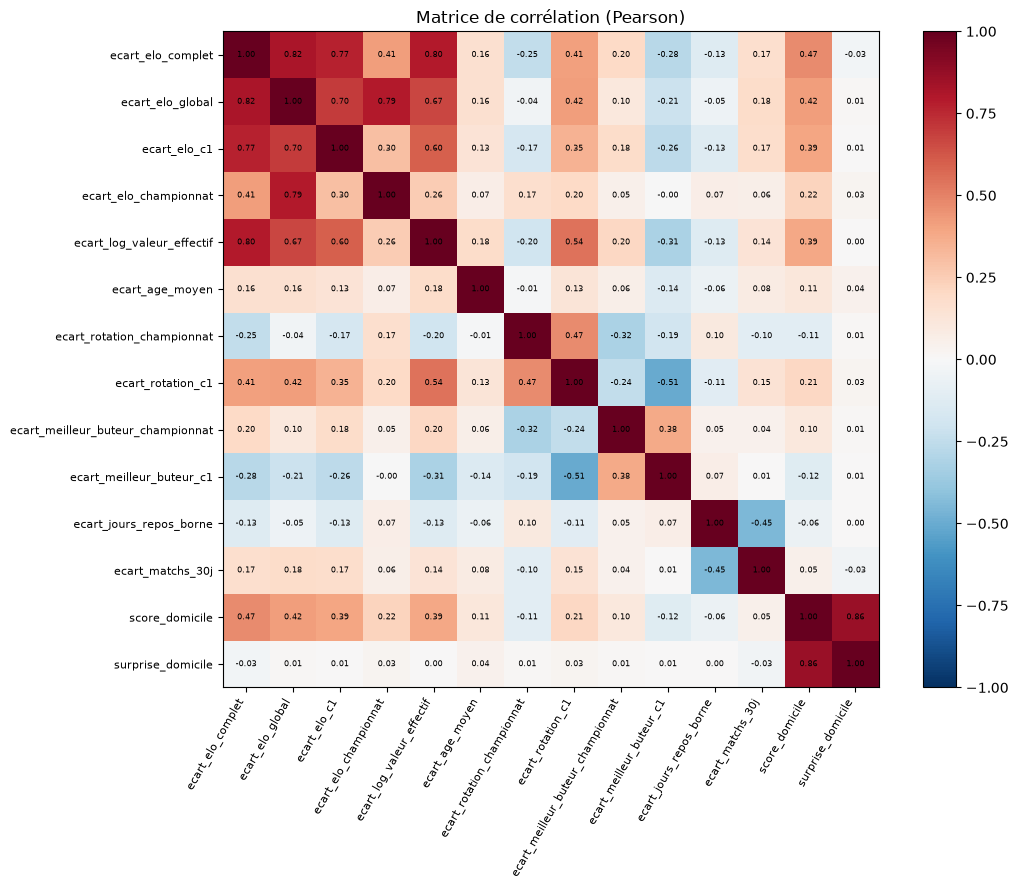

In [7]:
corr = g[VARIABLES_UTILES].corr(method="pearson")
corr_sp = g[VARIABLES_UTILES].corr(method="spearman")

n = len(VARIABLES_UTILES)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(n))
ax.set_xticklabels(VARIABLES_UTILES, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(n))
ax.set_yticklabels(VARIABLES_UTILES, fontsize=8)
for i in range(n):
    for j in range(n):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, fraction=0.04)
ax.set_title("Matrice de corrélation (Pearson)")
plt.tight_layout()
plt.show()

## 6. Quelles variables sont liées au résultat ?

**Question :** parmi nos 12 variables, lesquelles vont avec la victoire de l'équipe à domicile, et lesquelles apportent quelque chose **en plus de l'Elo** ?

Le tableau donne deux corrélations de Spearman :
- **avec le résultat** : Spearman compare des **rangs** (défaite < nul < victoire), il ne suppose donc pas qu'un nul vaut exactement « la moitié » d'une victoire ;
- **avec la surprise** : une variable liée à la surprise aide à prédire **ce que l'Elo complet n'avait pas prévu**.

**Résultat :**

| Variable | Lien avec le résultat | Lien avec la surprise |
|---|---|---|
| Écart d'**Elo complet** | **0,476** (le plus fort) | −0,01 |
| Écart de valeur de l'effectif | **0,446** | 0,03 |
| Écart d'Elo global (maison) | 0,416 | 0,02 |
| Écart d'Elo C1 | 0,404 | 0,02 |
| Écart d'Elo championnat | 0,221 | 0,03 |
| Rotation, buteur, âge | entre 0,10 et 0,19 | entre 0,01 et 0,03 |
| Repos, matchs sur 30 jours | −0,08 et 0,03 | ≈ 0 |

**Ce que montre la colonne « surprise » :** **aucune variable n'est vraiment liée à la surprise** (toutes entre −0,03 et +0,03). Une fois l'Elo complet connu, les autres variables, même la valeur de l'effectif, n'expliquent presque rien de plus, du moins pas en ligne droite.

**Le graphique** montre la répartition des **3 résultats** selon l'écart d'Elo complet, en 5 groupes de même taille :

| Écart d'Elo complet (domicile − extérieur) | Victoire domicile | Nul | Victoire extérieur |
|---|---|---|---|
| Très défavorable (moins de −165) | 19 % | 19 % | **61 %** |
| Défavorable (−165 à −48) | 31 % | **25 %** | 44 % |
| Équilibré (−48 à +51) | 44 % | **24 %** | 32 % |
| Favorable (+51 à +165) | 63 % | 20 % | 17 % |
| Très favorable (plus de +165) | **80 %** | 12 % | 7 % |

**Deux choses à voir :**
- les victoires à domicile passent de **19 % à 80 %** à mesure que l'équipe à domicile devient favorite ;
- **le nul est plus fréquent quand les équipes se valent** (24-25 %) et devient **rare** dans les matchs très déséquilibrés (12 %). C'est pour ça qu'il faut le traiter comme une catégorie à part : sa probabilité dépend de l'écart de niveau.

In [8]:
# Spearman compare des rangs (défaite < nul < victoire) : il ne suppose pas qu'un nul vaut exactement « la moitié »
cibles = ["score_domicile", "surprise_domicile"]
lien_resultat = pd.DataFrame({
    "lien avec le résultat": corr_sp["score_domicile"],
    "lien avec la surprise (au-delà de l'Elo)": corr_sp["surprise_domicile"],
}).drop(index=cibles)
lien_resultat.sort_values("lien avec le résultat", key=abs, ascending=False).round(3)

,lien avec le résultat,lien avec la surprise (au-delà de l'Elo)
ecart_elo_complet,0.476,-0.011
ecart_log_valeur_effectif,0.446,0.033
ecart_elo_global,0.416,0.024
ecart_elo_c1,0.404,0.020
ecart_elo_championnat,0.221,0.032
ecart_rotation_c1,0.191,0.006
ecart_rotation_championnat,-0.126,0.007
ecart_meilleur_buteur_championnat,0.111,0.019
ecart_meilleur_buteur_c1,-0.106,0.025
ecart_age_moyen,0.105,0.034


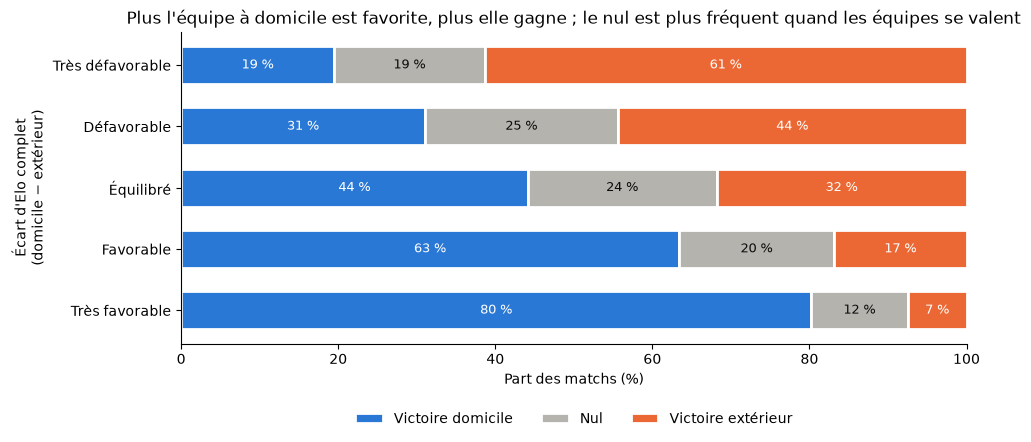

Bornes des groupes (points d'Elo) : [-165, -48, 51, 165]


resultat,Victoire domicile,Nul,Victoire extérieur
Très défavorable,19.5,19.2,61.3
Défavorable,31.0,24.6,44.4
Équilibré,44.1,24.1,31.8
Favorable,63.4,19.8,16.8
Très favorable,80.2,12.3,7.5


In [9]:
# Répartition victoire / nul / défaite selon l'écart d'Elo complet (5 groupes de même taille)
groupes = pd.qcut(g["ecart_elo_complet"], 5)
repartition = pd.crosstab(groupes, g["resultat"], normalize="index")[["Victoire domicile", "Nul", "Victoire extérieur"]] * 100
repartition.index = ["Très défavorable", "Défavorable", "Équilibré", "Favorable", "Très favorable"]

fig, ax = plt.subplots(figsize=(10, 4.6))
gauche = np.zeros(len(repartition))
for colonne, couleur, texte in zip(repartition.columns, ["#2a78d6", "#b5b3ad", "#eb6834"], ["white", "#0b0b0b", "white"]):
    ax.barh(repartition.index, repartition[colonne], left=gauche, color=couleur, label=colonne,
            height=0.62, edgecolor="white", linewidth=2)
    for y, (debut, valeur) in enumerate(zip(gauche, repartition[colonne])):
        ax.text(debut + valeur / 2, y, f"{valeur:.0f} %", ha="center", va="center", color=texte, fontsize=9)
    gauche += repartition[colonne].to_numpy()
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Part des matchs (%)")
ax.set_ylabel("Écart d'Elo complet\n(domicile − extérieur)")
ax.set_title("Plus l'équipe à domicile est favorite, plus elle gagne ; le nul est plus fréquent quand les équipes se valent")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print(f"Bornes des groupes (points d'Elo) : {[round(b) for b in groupes.cat.categories.right[:-1]]}")
repartition.round(1)

## 7. Quelles variables se répètent ?

**Question :** certaines variables disent-elles la même chose ? Deux variables très corrélées entre elles (au-delà de 0,5) apportent presque la même information. Les mettre toutes les deux dans un modèle ne l'aide pas, et peut même le perturber.

**Résultat :**

| Variables | Corrélation | Ce que ça veut dire |
|---|---|---|
| Elo complet / Elo global | **0,82** | Deux mesures du même niveau |
| Elo complet / valeur de l'effectif | **0,80** | Les clubs les plus riches sont aussi les mieux classés |
| Elo global / Elo championnat | 0,79 | L'Elo championnat est presque contenu dans l'Elo global |
| Elo complet / Elo C1 | 0,77 | Même idée pour l'Elo C1 |
| Elo global / Elo C1 | 0,70 | Idem |
| Elo global / valeur de l'effectif | 0,67 | Idem |
| Valeur de l'effectif / rotation C1 | 0,54 | Les clubs riches utilisent plus de joueurs en C1 (ils vont plus loin, donc jouent plus) |
| Rotation C1 / meilleur buteur C1 | −0,51 | Plus un club fait tourner, moins un seul joueur marque tous les buts |

**Ce que ça veut dire pour le modèle :** l'Elo complet et la valeur de l'effectif mesurent en grande partie **le même niveau** (0,80). Le modèle partira de l'**Elo complet**, et on vérifiera si la valeur de l'effectif **ajoute** vraiment quelque chose.

In [10]:
predicteurs = [v for v in VARIABLES_UTILES if v not in ("score_domicile", "surprise_domicile")]
paires = [
    (a, b, round(corr.loc[a, b], 3))
    for i, a in enumerate(predicteurs) for b in predicteurs[i + 1:]
    if abs(corr.loc[a, b]) >= 0.5
]
pd.DataFrame(paires, columns=["variable_1", "variable_2", "pearson"]) \
    .sort_values("pearson", key=abs, ascending=False)

,variable_1,variable_2,pearson
0,ecart_elo_complet,ecart_elo_global,0.815
2,ecart_elo_complet,ecart_log_valeur_effectif,0.796
4,ecart_elo_global,ecart_elo_championnat,0.791
1,ecart_elo_complet,ecart_elo_c1,0.770
3,ecart_elo_global,ecart_elo_c1,0.701
5,ecart_elo_global,ecart_log_valeur_effectif,0.670
6,ecart_elo_c1,ecart_log_valeur_effectif,0.601
7,ecart_log_valeur_effectif,ecart_rotation_c1,0.542
8,ecart_rotation_c1,ecart_meilleur_buteur_c1,-0.508


## 8. Interprétation

- **Le niveau des équipes est ce qui compte le plus.** Les variables les plus liées au résultat (Elo complet 0,476, valeur de l'effectif 0,446, Elo global 0,416, Elo C1 0,404) mesurent toutes le niveau de l'équipe. Le signe est positif : plus l'équipe à domicile est forte par rapport à son adversaire, plus elle gagne.
- **L'Elo complet est le meilleur indicateur.** Il couvre 100 % des matchs, remet les petits clubs à leur place et a le lien le plus fort avec le résultat.
- **Une fois l'Elo complet connu, les autres variables n'apportent presque rien de plus** : aucune n'est liée à la surprise (au plus 0,03). C'est une découverte importante pour le modèle.
- **Le nul dépend de l'écart de niveau** : 24-25 % quand les équipes se valent, 12 % quand l'une domine. Un modèle devra prédire sa probabilité, pas le traiter comme une demi-victoire.
- **L'Elo championnat est deux fois moins utile (0,22)** : un Elo national compare un club à son propre pays, pas aux clubs étrangers qu'il affronte en C1.
- **Le repos n'a pas d'effet.** Avant de retirer les clubs dont le championnat manque, la corrélation était de −0,22 ; après, elle tombe à **−0,08**. Ousmane l'a confirmé autrement : une fois le niveau pris en compte, le repos n'apporte rien (+0,007).
- **Les variables « joueurs » de la saison précédente** (rotation, meilleur buteur, âge) ont des liens faibles (0,10 à 0,19), et la rotation C1 n'est connue que pour 710 matchs sur 1 871.

## 9. Limite : la météo

*Argument, sans données météo dans le projet.* Le dépôt ne contient aucune donnée de température, de pluie ou de vent par match. Or le temps peut modifier le jeu (terrain lourd, vent, chaleur en fin d'été) et donc le résultat. Nous ne pouvons donc pas mesurer son effet. Pour le tester, il faudrait joindre à chaque match la météo du stade à l'heure du coup d'envoi (source ouverte à identifier, par exemple Meteostat), puis vérifier si elle améliore la corrélation ou le modèle. En attendant, la météo reste une **limite** du modèle, et nos résultats valent pour les conditions moyennes des matchs passés.

## 10. Corrélation ≠ causalité

Les variables ci-dessus sont **liées** au résultat, elles n'en sont pas la **cause** prouvée. Exemple : un écart d'Elo élevé et une victoire vont souvent ensemble parce que l'Elo résume le niveau de l'équipe, pas parce que l'Elo fait gagner. Une corrélation peut aussi venir d'une troisième variable (un club riche a à la fois une grande valeur d'effectif et plus de victoires). Nos résultats décrivent des associations observées sur les matchs passés.

In [11]:
OUT.mkdir(parents=True, exist_ok=True)
chemin = OUT / "eda_matchs_c1.csv"
g.to_csv(chemin, index=False, encoding="utf-8-sig")
print(f"Grande table écrite : {chemin} ({len(g):,} matchs)")

Grande table écrite : C:\Users\Mouss\AppData\Local\Temp\claude\C--Users-Mouss-OneDrive-Desktop-CHAMPIONS-\68928ccc-8961-4120-8d5a-872f13eac0eb\scratchpad\edav2\run\output\eda_matchs_c1.csv (1,871 matchs)


## 11. Conclusion

### 3 découvertes
1. **L'Elo complet est le meilleur indicateur du résultat** (0,476) : il couvre 100 % des clubs et les met à leur vraie place. Selon l'écart d'Elo complet, les victoires à domicile passent de **19 % à 80 %**.
2. **Une fois l'Elo complet connu, les autres variables n'ajoutent presque rien** : ni la valeur de l'effectif, ni le repos, ni la rotation ne sont liés à la surprise (au plus 0,03).
3. **Le nul dépend de l'écart de niveau** : 24-25 % entre équipes de même niveau, 12 % quand l'une domine. Il doit être traité comme une issue à part, pas comme une demi-victoire.

### 2 limites
1. **Des variables incomplètes ou estimées :** certains Elo complets sont estimés (erreur moyenne d'environ 43 points), la rotation C1 n'existe que pour 710 matchs sur 1 871, le repos pour 1 566, et certaines valeurs d'effectif sont sous-estimées pour de petits clubs.
2. **Aucune donnée météo**, et des corrélations qui ne prouvent pas une cause : corrélation ≠ causalité. La surprise ne mesure que des liens **en ligne droite** : un modèle pourrait trouver des effets plus fins.

### 1 question à poursuivre
Un modèle qui prédit les **3 issues** (victoire, nul, défaite) à partir de l'**Elo complet**, éventuellement avec la **valeur de l'effectif**, fait-il mieux que la règle « le meilleur Elo gagne » (**57,8 %**) ? C'est l'objet du notebook `MODEL_BASELINE.ipynb`.